In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# IMPORT
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import re
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import os
import matplotlib.pyplot as plt



root_path = "/content/drive/MyDrive/Action Recognition on UCF101"
src_path = os.path.join(root_path, "src")
split_path = os.path.join(root_path, "ucfTrainTestlist")

if src_path not in sys.path:
    sys.path.append(src_path)

#from dataset import UCF101Dataset
#from dataset import get_datasets
from dataset2 import UCF101DatasetFast
from dataset2 import get_datasets
from models import ResNet2D_Baseline, CustomCNN
from training import train_one_epoch, validate, get_next_run_id

In [4]:
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")

In [5]:
zip_path_drive = "/content/drive/MyDrive/Action Recognition on UCF101/UCF-101-JPG-zipped.zip"
local_root = "/content/data"
final_data_path = os.path.join(local_root, "temp_jpg_224")
if not os.path.exists(final_data_path):

    os.makedirs(local_root, exist_ok=True)

    !unzip -q -o "{zip_path_drive}" -d "{local_root}"

    print(f"Done! Data ready in: {final_data_path}")
else:
    print(f"Data already in {final_data_path}.")

# VERIFY
if os.path.exists(final_data_path):
    num_classes = len(os.listdir(final_data_path))
    print(f"Found {num_classes} classes in {final_data_path}")
else:
    print("Something gone wrong. Check zip name or path.")

Done! Data ready in: /content/data/temp_jpg_224
Found 101 classes in /content/data/temp_jpg_224


In [6]:
# HYPERPARAMETERS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
NUM_CLASSES = 101
FRAMES = 16

print(f"Using device: {DEVICE}")

Using device: cuda


In [7]:
data_root="/content/data/temp_jpg_224"
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")
config = {
    "DATA_ROOT" : data_root,
    "TRAIN_ANNOTATION_FILE": annotation_file_train,
    "TEST_ANNOTATION_FILE" : annotation_file_test,
    "CLASS_IND_FILE": class_ind_file,
    "FRAMES_PER_CLIP":16,
    "RESIZE_HEIGHT" : 224,
    "RESIZE_WIDTH" : 224
}
print("Loading Datasets...")
train_dataset, val_dataset, test_dataset = get_datasets(config)

Loading Datasets...
--------------------------------------------------
GROUP-BASED SPLIT SUMMARY:
Train samples: 7675
Val samples:   1862
Test samples:  3783
--------------------------------------------------
SUCCESS: No overlapping samples found between datasets.
--------------------------------------------------


In [8]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2) # Shuffle False per Val
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

 EXPERIMENT STARTED: ResNetCNN_baseline
 AUTO-ASSIGNED ID:   Run_04
 OUTPUT FOLDER:      /content/drive/MyDrive/Action Recognition on UCF101/experiments/ResNetCNN_baseline/Run_04
Initializing Model...

Starting Training loop for 50 epochs...
Stop condition: No validation loss improvement (delta=0.001) for 10 epochs.

Epoch 1/50


Validation: 100%|██████████| 117/117 [00:28<00:00,  4.05it/s]


 -> Train Loss: 4.1465 | Acc: 15.58%
 -> Val Loss:   3.5587 | Acc: 30.34%
    >>> New Best Validation Accuracy! Model saved.
Epoch 2/50


Validation: 100%|██████████| 117/117 [00:29<00:00,  3.91it/s]


 -> Train Loss: 2.9944 | Acc: 53.06%
 -> Val Loss:   2.7442 | Acc: 52.63%
    >>> New Best Validation Accuracy! Model saved.
Epoch 3/50


Validation: 100%|██████████| 117/117 [00:28<00:00,  4.12it/s]


... (69 outputs left out)

Validation: 100%|██████████| 117/117 [00:29<00:00,  3.97it/s]


 -> Train Loss: 0.0055 | Acc: 99.99%
 -> Val Loss:   0.9690 | Acc: 75.56%
!!! No improvement. Patience: 9/10
Epoch 39/50


Validation: 100%|██████████| 117/117 [00:28<00:00,  4.08it/s]


 -> Train Loss: 0.0047 | Acc: 100.00%
 -> Val Loss:   0.9731 | Acc: 75.19%
!!! No improvement. Patience: 10/10

EARLY STOPPING TRIGGERED.
   Stopping training to prevent overfitting.

 TRAINING COMPLETE
Generating training plots...


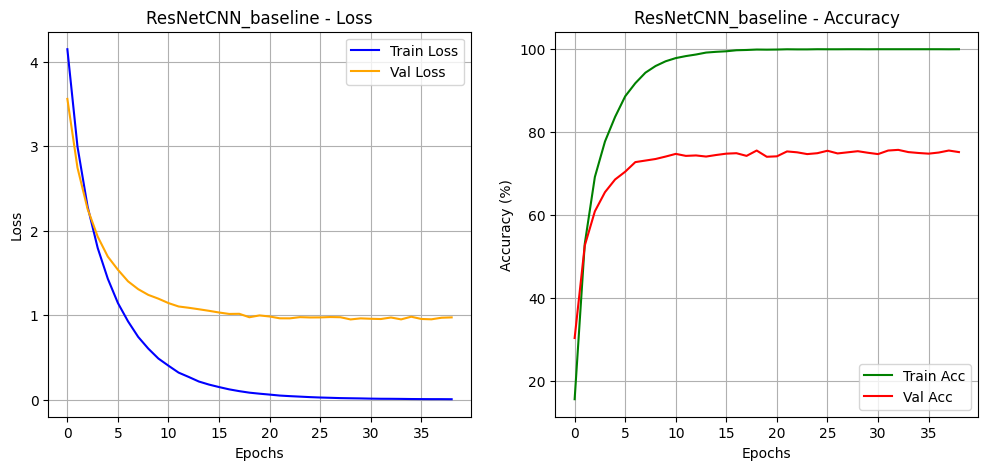

In [10]:
VARIANT_NAME = "ResNetCNN_baseline"
EXPERIMENTS_ROOT = os.path.join(root_path, "experiments", VARIANT_NAME)

# CONFIGURATION FOLDER
RUN_ID = get_next_run_id(EXPERIMENTS_ROOT)
checkpoint_dir = os.path.join(EXPERIMENTS_ROOT, RUN_ID)
best_model_path = os.path.join(checkpoint_dir, "best_model.pth")
plot_path = os.path.join(checkpoint_dir, "training_curves.png")

os.makedirs(checkpoint_dir, exist_ok=True)

print(f"==================================================")
print(f" EXPERIMENT STARTED: {VARIANT_NAME}")
print(f" AUTO-ASSIGNED ID:   {RUN_ID}")
print(f" OUTPUT FOLDER:      {checkpoint_dir}")
print(f"==================================================")

# HYPERPARAMETERS
PATIENCE = 10
EARLY_STOPPING_DELTA = 0.001
LEARNING_RATE = 1e-5
NUM_EPOCHS = 50

# Initialize model
print("Initializing Model...")
model = ResNet2D_Baseline(num_classes=NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_loss_hist = []
val_loss_hist = []
train_acc_hist = []
val_acc_hist = []

best_val_acc = 0.0
min_val_loss = float('inf')
early_stopping_counter = 0

print(f"\nStarting Training loop for {NUM_EPOCHS} epochs...")
print(f"Stop condition: No validation loss improvement (delta={EARLY_STOPPING_DELTA}) for {PATIENCE} epochs.\n")

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # TRAIN STEP
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # VALIDATION STEP
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    # Print metrics
    print(f" -> Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f" -> Val Loss:   {val_loss:.4f} | Acc: {val_acc:.2f}%")

    # CHECKPOINT SAVING
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"    >>> New Best Validation Accuracy! Model saved.")

    # EARLY STOPPING LOGIC
    if val_loss < (min_val_loss - EARLY_STOPPING_DELTA):
        min_val_loss = val_loss
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1
        print(f"!!! No improvement. Patience: {early_stopping_counter}/{PATIENCE}")

        if early_stopping_counter >= PATIENCE:
            print(f"\nEARLY STOPPING TRIGGERED.")
            print("   Stopping training to prevent overfitting.")
            break

print("\n" + "="*50)
print(" TRAINING COMPLETE")
print("="*50)

print("Generating training plots...")

plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_hist, label='Train Loss', color='blue')
plt.plot(val_loss_hist, label='Val Loss', color='orange')
plt.title(f'{VARIANT_NAME} - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_acc_hist, label='Train Acc', color='green')
plt.plot(val_acc_hist, label='Val Acc', color='red')
plt.title(f'{VARIANT_NAME} - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.show()

In [11]:
# Check the first 10 labels of the test set
test_labels = [test_dataset.samples[i][1] for i in range(10)]
unique_test_labels = set([s[1] for s in test_dataset.samples])

print(f"First 10 test labels: {test_labels}")
print(f"Number of unique classes in test set: {len(unique_test_labels)}")
print(f"Unique labels found: {unique_test_labels}")

First 10 test labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of unique classes in test set: 1
Unique labels found: {0}


In [12]:
# RECOVER CLASS MAPPING
class_to_idx = {}

for path, label in train_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))
    class_to_idx[class_name] = label

print(f"Mapping reconstructed for {len(class_to_idx)} classes.")

# APPLY MAPPING TO TEST DATASET (REPAIR)
# This step ensures that the test labels are synchronized with the training labels
repaired_samples = []
for path, old_label in test_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))

    if class_name in class_to_idx:
        new_label = class_to_idx[class_name]
        repaired_samples.append((path, new_label))
    else:
        # Fallback: keep the original label if the class is not found in the training set
        repaired_samples.append((path, old_label))

# Update the test dataset samples with the corrected labels
test_dataset.samples = repaired_samples

# FINAL VERIFICATION
unique_labels = set([s[1] for s in test_dataset.samples])
print(f"Verification complete: Found {len(unique_labels)} unique classes in the Test Set.")

Mapping reconstructed for 101 classes.
Verification complete: Found 101 unique classes in the Test Set.


In [13]:
def perform_final_evaluation(model, test_loader, best_model_path, train_dataset, device):
    print("--- STARTING FINAL EXTENDED EVALUATION ---")

    idx_to_class = {}
    for path, label in train_dataset.samples:
        class_name = os.path.basename(os.path.dirname(path))
        if label not in idx_to_class:
            idx_to_class[label] = class_name


    model.load_state_dict(torch.load(best_model_path))
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    print("Running inference on test set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)


    final_acc = (all_preds == all_labels).mean() * 100
    print(f"\nFINAL TEST ACCURACY: {final_acc:.2f}%")
    print("-" * 40)


    target_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]
    full_report = classification_report(all_labels, all_preds, target_names=target_names, digits=4)
    print("\nCLASSIFICATION REPORT:")
    print(full_report)


    cm = confusion_matrix(all_labels, all_preds)
    per_class_acc = np.divide(cm.diagonal(), cm.sum(axis=1),
                              out=np.zeros_like(cm.diagonal(), dtype=float),
                              where=cm.sum(axis=1)!=0)


    performance_df = pd.DataFrame({
        'Class_Name': [idx_to_class.get(i, f"Unknown_{i}") for i in range(len(per_class_acc))],
        'Accuracy': per_class_acc
    }).sort_values(by='Accuracy', ascending=True)

    print("\nTOP 5 MOST DIFFICULT CLASSES (Lowest Accuracy):")

    print(performance_df.head(5).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    print("\nTOP 5 BEST PERFORMING CLASSES (Highest Accuracy):")
    print(performance_df.tail(5).sort_values(by='Accuracy', ascending=False).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    return all_labels, all_preds, performance_df

labels, preds, class_stats = perform_final_evaluation(model, test_loader, best_model_path, train_dataset, DEVICE)

--- STARTING FINAL EXTENDED EVALUATION ---
Running inference on test set...

FINAL TEST ACCURACY: 75.71%
----------------------------------------

CLASSIFICATION REPORT:
                    precision    recall  f1-score   support

    ApplyEyeMakeup     0.8780    0.8182    0.8471        44
     ApplyLipstick     0.8000    1.0000    0.8889        32
           Archery     0.6757    0.6098    0.6410        41
      BabyCrawling     0.6250    0.8571    0.7229        35
       BalanceBeam     0.8000    0.9032    0.8485        31
      BandMarching     0.7119    0.9767    0.8235        43
     BaseballPitch     0.9487    0.8605    0.9024        43
        Basketball     0.5094    0.7714    0.6136        35
    BasketballDunk     0.9487    1.0000    0.9737        37
        BenchPress     0.8776    0.8958    0.8866        48
            Biking     1.0000    0.8421    0.9143        38
         Billiards     1.0000    1.0000    1.0000        40
       BlowDryHair     0.5714    0.6316    0.6000